# **Step 6 of 7: HDBSCAN Clustering (HR Employees)**

**HDBSCAN** (Hierarchical DBSCAN) combines the ideas of DBSCAN and hierarchical clustering. It builds the cluster tree for **all** `eps` values at once and keeps the clusters that are **most stable** (live longest). So it needs **no `eps`**, finds clusters of **different densities**, and labels outliers as noise.

Main parameters:
- `min_cluster_size`: smallest group that may be called a cluster (the most important parameter)
- `min_samples`: how conservative the noise detection is (bigger = more noise)
- `cluster_selection_method`: `'eom'` (fewer, bigger, stable clusters) or `'leaf'` (more, smaller clusters)

Bonus: every employee gets a **membership probability** (how strongly it belongs to its cluster). Employees with a low probability sit at the edge of a cluster.

Good for: real-world data with noise and different densities. This is usually the easiest density-based method to tune.

### 1. Import and load the preprocessed data
This notebook uses the files made in **step 1 (01_HR_Data_Preprocessing)**:
- `hr_clean.csv`: cleaned data in original units (used to describe the clusters)
- `hr_preprocessed.csv`: scaled clustering features (used by the algorithm)
- `hr_scaler.pkl`, `preprocessing_info.json` (and `hr_truth.csv`, demo data only)

Keep these files in the same folder as this notebook.

> The data is **synthetic demo data** (about 4 hidden employee groups + 3% unusual employees). Because we know the hidden groups, the result can also be checked with *external* metrics. With real HR data this check is not possible and only the internal metrics are used.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
sns.set_theme(style='whitegrid')

# ---- files made by 01_HR_Data_Preprocessing.ipynb (keep them in the same folder) ----
need = ['hr_clean.csv', 'hr_preprocessed.csv', 'preprocessing_info.json', 'hr_scaler.pkl']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Run 01_HR_Data_Preprocessing.ipynb first. Missing files: {missing}')

info = json.load(open('preprocessing_info.json'))
FEATURES, PROFILE_COLS = info['features'], info['profile_cols']

df = pd.read_csv('hr_clean.csv')                    # cleaned data, original units (used to describe the clusters)
X_df = pd.read_csv('hr_preprocessed.csv')           # scaled features (used by the algorithm)
assert (df['employee_id'].values == X_df['employee_id'].values).all(), 'files do not match'
X = X_df[FEATURES].values
scaler = joblib.load('hr_scaler.pkl')               # needed to prepare NEW employees

# hidden true groups: exist only in the synthetic demo data, used only to check the result at the end
if os.path.exists('hr_truth.csv'):
    df = df.merge(pd.read_csv('hr_truth.csv'), on='employee_id', how='left')
HAS_TRUTH = 'segment_true' in df.columns

print('Employees:', X.shape[0], '| clustering features:', FEATURES)
print('Hopkins statistic from step 1:', info['hopkins'], '| hidden truth available:', HAS_TRUTH)
df.head()

Employees: 1498 | clustering features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Hopkins statistic from step 1: 0.747 | hidden truth available: True


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr,segment_true
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0,Engaged high performers
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0,Loyal long-tenure
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0,Engaged high performers
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0,Loyal long-tenure
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0,Disengaged underused


Helper functions used in all sections (metrics, plots, cluster profile):

In [2]:
def internal_metrics(X, labels):
    """Internal metrics (no true labels needed). Noise points (-1) are ignored."""
    labels = np.asarray(labels); mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = {'n_clusters': n_clusters, 'noise_%': round(100 * (~mask).mean(), 1),
           'silhouette': np.nan, 'calinski_harabasz': np.nan, 'davies_bouldin': np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out['silhouette'] = silhouette_score(X[mask], labels[mask])
        out['calinski_harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        out['davies_bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    return out

def external_metrics(truth, labels):
    """External metrics: compare with the hidden true segments (demo data only)."""
    h, c, v = homogeneity_completeness_v_measure(truth, labels)
    return {'ARI': adjusted_rand_score(truth, labels), 'NMI': normalized_mutual_info_score(truth, labels),
            'homogeneity': h, 'completeness': c, 'v_measure': v}

def plot_clusters(Z, labels, ax, title, centers=None):
    """2D scatter of the clusters (Z = PCA coordinates). Noise = black x."""
    labels = np.asarray(labels); palette = sns.color_palette('tab10', 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c='black', marker='x', s=25, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, color=palette[lab % 10], label=f'Cluster {lab} ({m.sum()})')
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centers')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)

def cluster_profile(data, labels):
    """Average of every feature in each cluster (original units) + size."""
    labels = np.asarray(labels)
    prof = data[PROFILE_COLS].assign(cluster=labels).groupby('cluster').mean()
    prof['size'] = pd.Series(labels).value_counts().sort_index()
    prof['share_%'] = (100 * prof['size'] / len(labels)).round(1)
    return prof

def plot_profile(prof, title='Cluster profile (colour = high / low compared with other clusters, number = real average)'):
    feat = prof[PROFILE_COLS]
    z = (feat - feat.mean()) / (feat.std(ddof=0) + 1e-9)
    plt.figure(figsize=(9, 0.9 * len(prof) + 2))
    sns.heatmap(z, annot=feat.round(2), fmt='g', cmap='RdYlGn', center=0, cbar_kws={'label': 'relative level'})
    plt.title(title); plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

### 2. Look at the data

In [3]:
df[PROFILE_COLS].describe().round(2)

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level
count,1498.00,1498.00,1498.00,1498.00,1498.00,1498.00
mean,0.55,0.73,4.12,196.67,4.76,0.93
std,0.23,0.16,1.45,47.51,2.24,0.74
min,0.09,0.36,2.00,96.00,2.00,0.00
25%,0.35,0.60,3.00,160.00,3.00,0.00
50%,0.57,0.77,4.00,191.00,4.00,1.00
75%,0.76,0.86,5.00,222.00,6.00,1.00
max,1.00,1.00,7.00,310.00,10.00,2.00


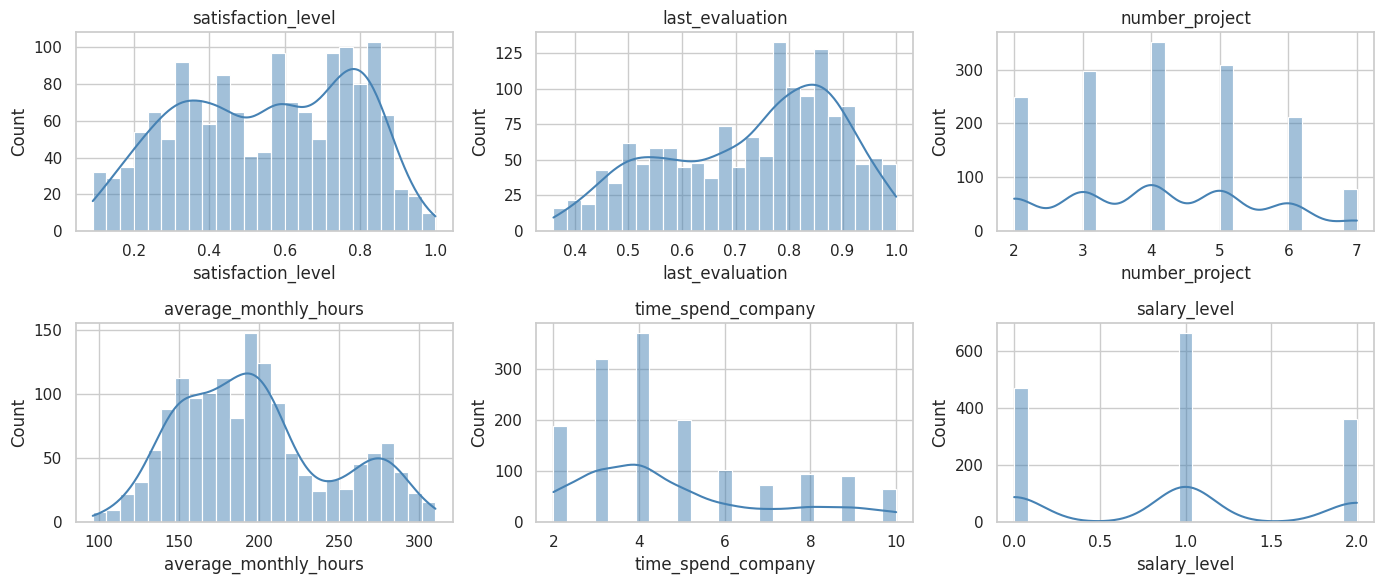

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, f in zip(ax.ravel(), PROFILE_COLS):
    sns.histplot(df[f], bins=25, kde=True, ax=a, color='steelblue')
    a.set_title(f)
plt.tight_layout(); plt.show()

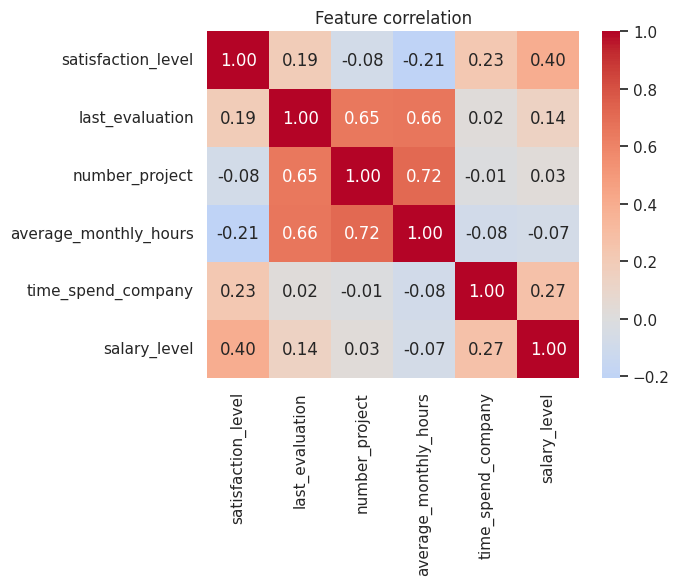

In [5]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[PROFILE_COLS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation'); plt.show()

### 3. 2D view for plotting (PCA)
The data is already **cleaned and scaled in step 1**, so no preprocessing is needed here. PCA is used **only to draw** the clusters in 2D (the clustering itself uses all features).

In [6]:
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print('Variance explained by the 2 plotted components:', (pca.explained_variance_ratio_.sum() * 100).round(1), '%')

Variance explained by the 2 plotted components: 72.9 %


### 4. Tune `min_cluster_size`, `min_samples`, `cluster_selection_method` (grid search)
Every combination is judged with **internal metrics** + number of clusters + % noise.

In [7]:
from sklearn.cluster import HDBSCAN

In [8]:
# Selection rule: 2 to 8 clusters, at most 20% noise, then the best silhouette.
# (Silhouette alone would prefer 'a tiny dense cluster + almost everything else noise', so the rule keeps the result useful.)
# If nothing fits, the rule is relaxed step by step.
def pick_best(res, max_noise=20, min_c=2, max_c=8):
    res = res.dropna(subset=['silhouette'])
    for noise, cmin, cmax in [(max_noise, min_c, max_c), (35, min_c, 12), (60, 2, 20)]:
        ok = res[(res['n_clusters'] >= cmin) & (res['n_clusters'] <= cmax) & (res['noise_%'] <= noise)]
        if len(ok):
            return ok.sort_values('silhouette', ascending=False)
    return res.sort_values('silhouette', ascending=False)

Top 8 settings by the selection rule:


,min_cluster_size,min_samples,method,n_clusters,noise_%,silhouette,calinski_harabasz,davies_bouldin
16,30,30,eom,3,18.8,0.506,1310.591,0.750
6,10,20,eom,3,18.8,0.504,1300.542,0.754
8,20,20,eom,3,18.8,0.504,1300.542,0.754
14,20,20,eom,3,18.8,0.504,1300.542,0.754
30,50,20,eom,3,18.8,0.504,1300.542,0.754
22,30,20,eom,3,18.8,0.504,1300.542,0.754
47,120,20,leaf,3,18.8,0.504,1300.542,0.754
38,80,20,eom,3,18.8,0.504,1300.542,0.754


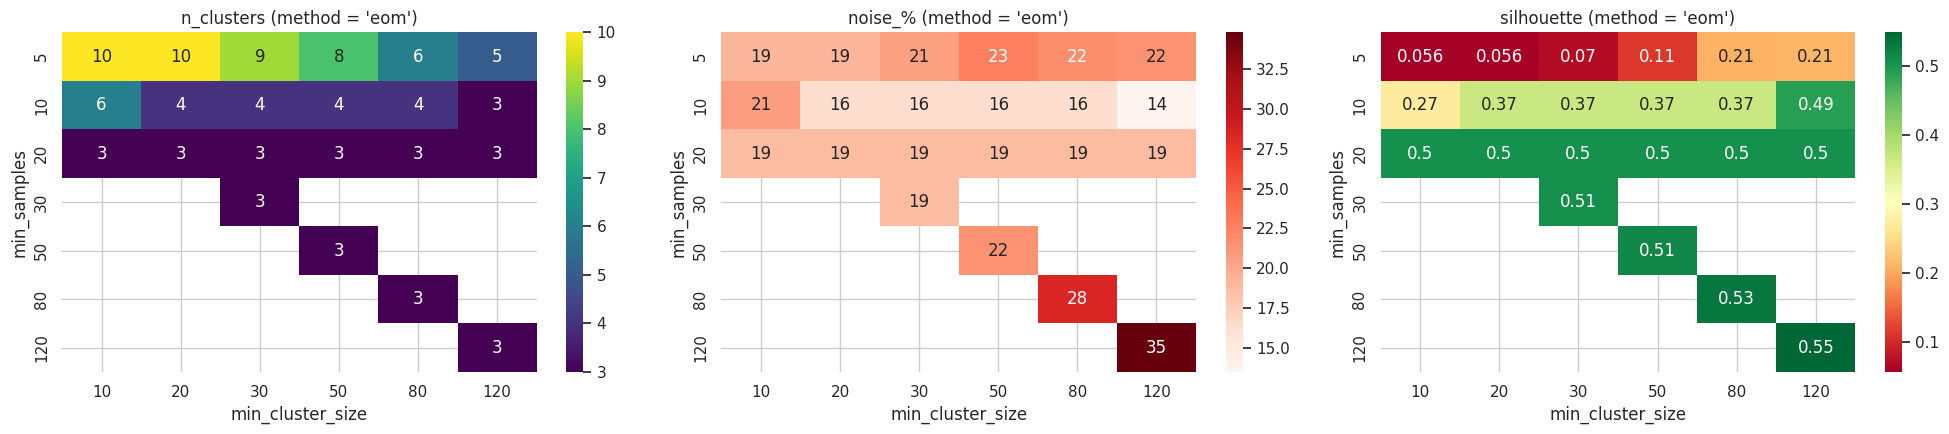

In [9]:
rows = []
for mcs in [10, 20, 30, 50, 80, 120]:
    for ms in [None, 5, 10, 20]:
        for method in ['eom', 'leaf']:
            lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=method).fit(X).labels_
            rows.append({'min_cluster_size': mcs, 'min_samples': ms if ms else mcs, 'method': method, **internal_metrics(X, lab)})
grid = pd.DataFrame(rows)
print('Top 8 settings by the selection rule:')
display(pick_best(grid).head(8).round(3))

fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for a, col, cmap in zip(ax, ['n_clusters', 'noise_%', 'silhouette'], ['viridis', 'Reds', 'RdYlGn']):
    sns.heatmap(grid[grid['method'] == 'eom'].pivot_table(index='min_samples', columns='min_cluster_size', values=col),
                annot=True, fmt='.2g', cmap=cmap, ax=a)
    a.set_title(f"{col} (method = 'eom')")
plt.tight_layout(); plt.show()

### 5. Final HDBSCAN model

In [10]:
best = pick_best(grid).iloc[0]
MCS, MS, METHOD = int(best['min_cluster_size']), int(best['min_samples']), best['method']     # change to try others

hdb = HDBSCAN(min_cluster_size=MCS, min_samples=MS, cluster_selection_method=METHOD).fit(X)
labels = hdb.labels_
print(f"min_cluster_size = {MCS} | min_samples = {MS} | method = '{METHOD}'")
print(pd.Series(labels).value_counts().sort_index().rename('employees').to_string())

min_cluster_size = 30 | min_samples = 30 | method = 'eom'
-1    282
 0    236
 1    651
 2    329


### 6. Evaluation metrics

In [11]:
metrics = internal_metrics(X, labels)
print('===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====')
print('Clusters found     :', metrics['n_clusters'], '| noise points:', metrics['noise_%'], '%')
print('Silhouette         :', round(metrics['silhouette'], 4), ' (higher is better)')
print('Calinski-Harabasz  :', round(metrics['calinski_harabasz'], 1), ' (higher is better)')
print('Davies-Bouldin     :', round(metrics['davies_bouldin'], 4), ' (lower is better)')

if HAS_TRUTH:
    ext = external_metrics(df['segment_true'], labels)
    print('\n===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====')
    for k_, v_ in ext.items():
        print(f'{k_:<13}: {v_:.4f}')

===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====
Clusters found     : 3 | noise points: 18.8 %
Silhouette         : 0.506  (higher is better)
Calinski-Harabasz  : 1310.6  (higher is better)
Davies-Bouldin     : 0.7501  (lower is better)

===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====
ARI          : 0.5438
NMI          : 0.6356
homogeneity  : 0.5990
completeness : 0.6770
v_measure    : 0.6356


**Membership probability:** how sure HDBSCAN is that an employee belongs to its cluster (noise points have probability 0).

Average membership probability (clustered employees): 0.923
Employees with probability < 0.5 (edge of a cluster): 0


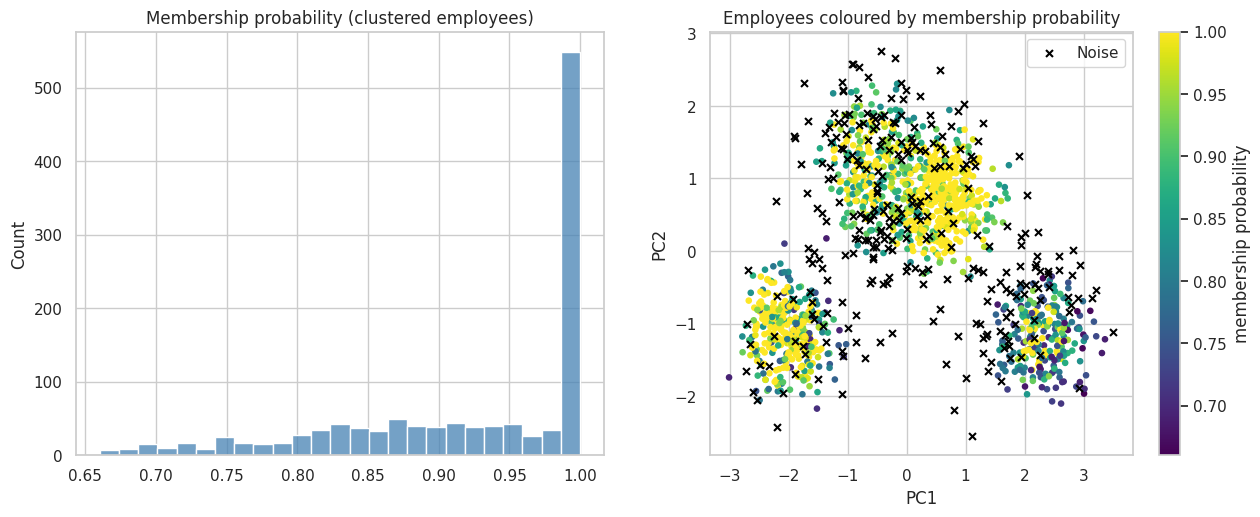

In [12]:
prob = hdb.probabilities_
print('Average membership probability (clustered employees):', round(prob[labels != -1].mean(), 3))
print('Employees with probability < 0.5 (edge of a cluster):', int(((prob < 0.5) & (labels != -1)).sum()))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.histplot(prob[labels != -1], bins=25, color='steelblue', ax=ax[0]); ax[0].set_title('Membership probability (clustered employees)')
sc = ax[1].scatter(Z[labels != -1, 0], Z[labels != -1, 1], c=prob[labels != -1], cmap='viridis', s=14)
ax[1].scatter(Z[labels == -1, 0], Z[labels == -1, 1], c='black', marker='x', s=25, label='Noise')
plt.colorbar(sc, ax=ax[1], label='membership probability'); ax[1].set_title('Employees coloured by membership probability')
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); ax[1].legend(); plt.show()

### 7. Visualization
Black **x** = noise.

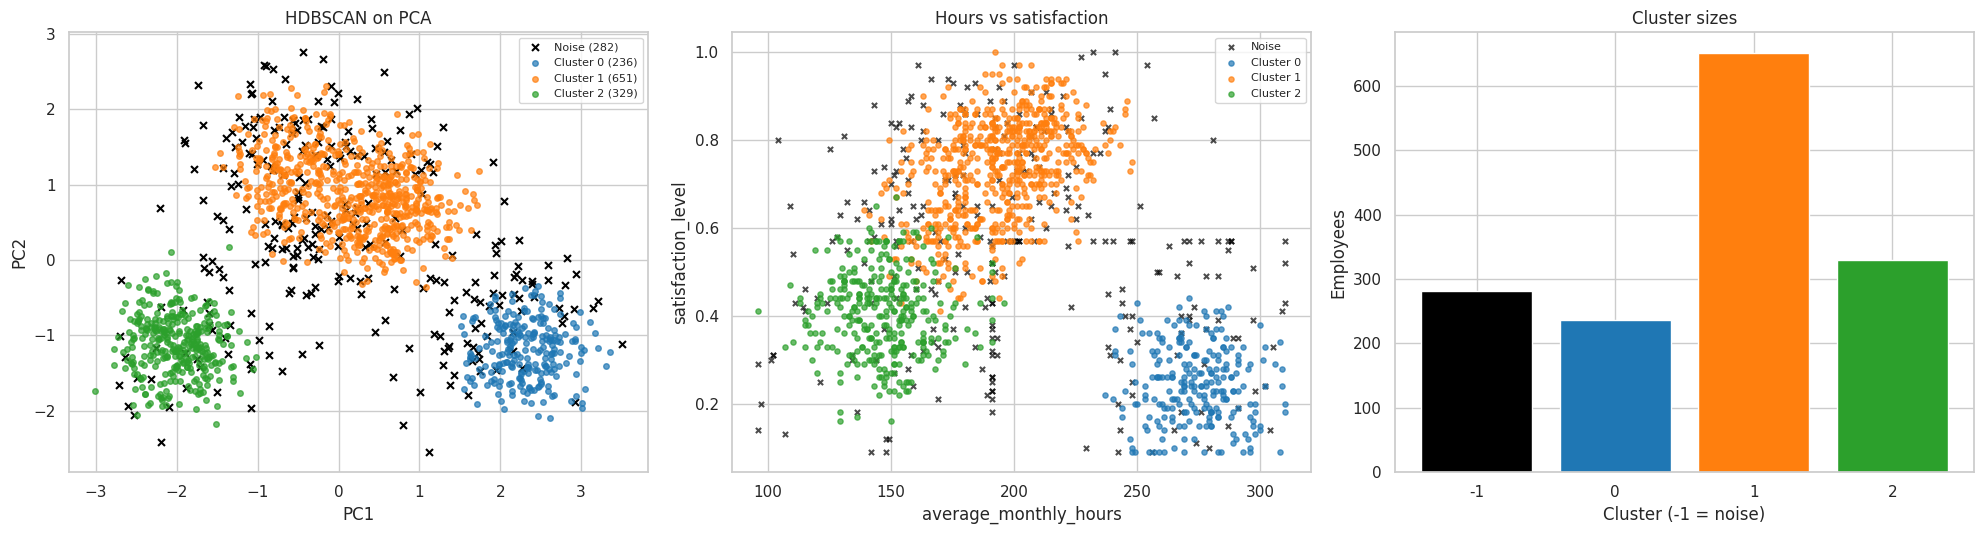

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
plot_clusters(Z, labels, ax[0], 'HDBSCAN on PCA')

for c in sorted(set(labels)):
    m = labels == c
    ax[1].scatter(df.loc[m, 'average_monthly_hours'], df.loc[m, 'satisfaction_level'], s=14, alpha=0.7,
                  color='black' if c == -1 else sns.color_palette('tab10')[c % 10], marker='x' if c == -1 else 'o',
                  label='Noise' if c == -1 else f'Cluster {c}')
ax[1].set_xlabel('average_monthly_hours'); ax[1].set_ylabel('satisfaction_level'); ax[1].set_title('Hours vs satisfaction'); ax[1].legend(fontsize=8)

sizes = pd.Series(labels).value_counts().sort_index()
ax[2].bar(sizes.index.astype(str), sizes.values, color=['black' if i == -1 else sns.color_palette('tab10')[i % 10] for i in sizes.index])
ax[2].set_xlabel('Cluster (-1 = noise)'); ax[2].set_ylabel('Employees'); ax[2].set_title('Cluster sizes')
plt.tight_layout(); plt.show()

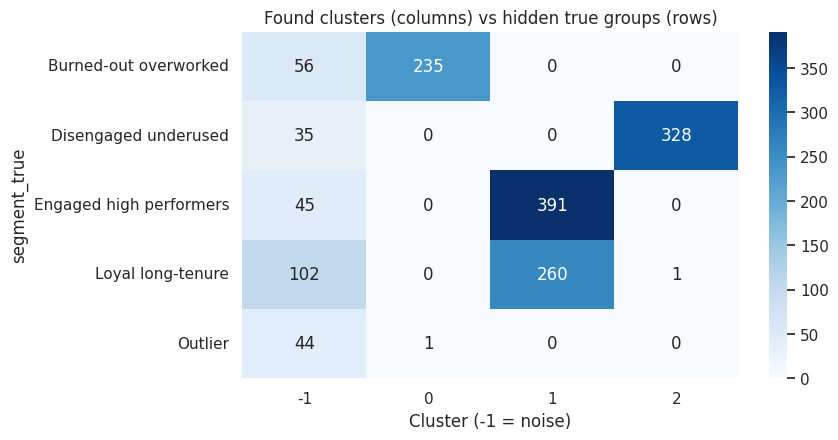

In [14]:
if HAS_TRUTH:
    plt.figure(figsize=(8, 4.5))
    sns.heatmap(pd.crosstab(df['segment_true'], labels), annot=True, fmt='d', cmap='Blues')
    plt.title('Found clusters (columns) vs hidden true groups (rows)'); plt.xlabel('Cluster (-1 = noise)'); plt.show()

**What to notice in this demo data (this run):**
- HDBSCAN finds **3 clusters** (K-Means found 4). Like DBSCAN, it puts the two touching groups *Engaged high performers* and *Loyal long-tenure* into **one cluster**, because there is no empty gap between them.
- It is very good at the **unusual employees**: 44 of the 45 real random outliers are labelled noise (-1).
- The noise (about 19%) also contains many *Loyal long-tenure* employees (long tenure is an unusual value), so **noise is not always "bad data"**. Membership probabilities (section 6) show how sure HDBSCAN is about each employee.

### Cluster profile: who is in each cluster?
Green = high, red = low compared with the other clusters. Cluster -1 (if present) = noise / unusual employees.

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,size,share_%
cluster,,,,,,,,
-1,0.55,0.73,4.29,197.84,5.69,1.00,282,18.8
0,0.24,0.88,6.00,273.92,3.87,0.50,236,15.8
1,0.73,0.79,4.22,193.35,5.50,1.26,651,43.5
2,0.41,0.51,2.40,146.83,3.12,0.51,329,22.0


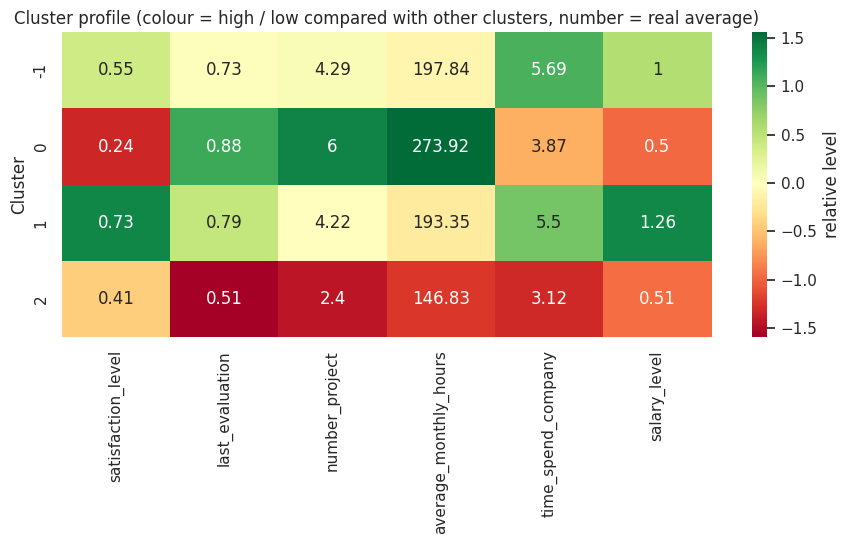

In [15]:
prof = cluster_profile(df, labels)
display(prof.round(2))
plot_profile(prof)

### Assign new employees and save
This algorithm has no `predict` method for new data. A common solution: train a small **KNN classifier on the found cluster labels** and use it to place new employees in the nearest cluster.

In [16]:
mask = labels != -1
assigner = KNeighborsClassifier(n_neighbors=5).fit(X[mask], labels[mask])

new = pd.DataFrame({'satisfaction_level': [0.15, 0.85, 0.45], 'last_evaluation': [0.90, 0.88, 0.50],
                    'number_project': [7, 5, 2], 'average_monthly_hours': [280, 210, 140],
                    'time_spend_company': [4, 3, 3]})
new['cluster'] = assigner.predict(scaler.transform(new[FEATURES]))
display(new)

joblib.dump({'scaler': scaler, 'model': hdb, 'assigner': assigner, 'features': FEATURES, 'profile': prof}, 'hdbscan_hr_model.pkl')
df.assign(cluster=labels).to_csv('hr_hdbscan_clusters.csv', index=False)
print('Saved: hdbscan_hr_model.pkl, hr_hdbscan_clusters.csv')

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,cluster
0,0.15,0.90,7,280,4,0
1,0.85,0.88,5,210,3,1
2,0.45,0.50,2,140,3,2


Saved: hdbscan_hr_model.pkl, hr_hdbscan_clusters.csv


### Download (Google Colab only)

In [17]:
try:
    from google.colab import files
    files.download('hdbscan_hr_model.pkl'); files.download('hr_hdbscan_clusters.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
